# Project Data Science IF-C
### Nama Kelompok : Bersifat Opsional

## 1. Persiapan Environtment & Import Library

### 1.1 Install Library

In [2]:
#pip install pandas numpy scikit-learn matplotlib seaborn

## 1.2 Import Library yang Dibutuhkan

In [ ]:
# import seaborn as sns
# import numpy as np
# import matplotlib.pyplot as plt
# import pandas as pd

# from sklearn.model_selection import train_test_split
# from sklearn.linear_model import LinearRegression, Ridge, Lasso
# from sklearn.preprocessing import StandardScaler
# from sklearn.metrics import mean_squared_error, r2_score

## 1.3 Load Dataset

In [ ]:
import pandas as pd

df = pd.read_csv("../Data/used_car.csv")
print("dataset berhasil diload!")

dataset berhasil diload!


# 2. Data Understanding

## 2.1 Pengenalan Dataset used_car.csv

In [5]:
print(df.head())

                car name     brand  year  mileage (km)           location  \
0             AYLA X 1.2  Daihatsu  2018        10.508      Jakarta Utara   
1  AGYA TRD SPORTIVO 1.0    Toyota  2015       112.888              Bogor   
2            X-TRAIL 2.5    Nissan  2015       118.429           Surabaya   
3        YARIS S TRD 1.5    Toyota  2020        15.945  Tangerang Selatan   
4             AGYA G 1.2    Toyota  2019        30.404      Jakarta Barat   

  transmission  plate type  rear camera  sun roof  auto retract mirror  \
0       Manual  even plate            0         0                    0   
1       Manual  even plate            0         0                    0   
2    Automatic   odd plate            0         0                    0   
3    Automatic   odd plate            0         0                    0   
4       Manual   odd plate            0         0                    0   

   electric parking brake  map navigator  vehicle stability control  \
0                    

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 609 entries, 0 to 608
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   car name                   609 non-null    object 
 1   brand                      609 non-null    object 
 2   year                       609 non-null    int64  
 3   mileage (km)               609 non-null    float64
 4   location                   609 non-null    object 
 5   transmission               609 non-null    object 
 6   plate type                 609 non-null    object 
 7   rear camera                609 non-null    int64  
 8   sun roof                   609 non-null    int64  
 9   auto retract mirror        609 non-null    int64  
 10  electric parking brake     609 non-null    int64  
 11  map navigator              609 non-null    int64  
 12  vehicle stability control  609 non-null    int64  
 13  keyless push start         609 non-null    int64  

In [7]:
print(df.describe())

              year  mileage (km)  rear camera    sun roof  \
count   609.000000     609.00000   609.000000  609.000000   
mean   2018.049261      61.68579     0.142857    0.029557   
std       2.029601      32.14993     0.350215    0.169500   
min    2010.000000       1.06500     0.000000    0.000000   
25%    2017.000000      39.14500     0.000000    0.000000   
50%    2018.000000      58.36500     0.000000    0.000000   
75%    2019.000000      81.72600     0.000000    0.000000   
max    2023.000000     245.00000     1.000000    1.000000   

       auto retract mirror  electric parking brake  map navigator  \
count           609.000000              609.000000     609.000000   
mean              0.469622                0.031199       0.009852   
std               0.499487                0.173997       0.098849   
min               0.000000                0.000000       0.000000   
25%               0.000000                0.000000       0.000000   
50%               0.000000          

In [8]:
print('jumlah (baris, kolom) data: ', df.shape)

jumlah (baris, kolom) data:  (609, 20)


### 2.2 Data Dictionary

In [9]:
deskripsi_kolom = {
    "car name": "Nama model atau varian mobil",
    "brand": "Merek kendaraan",
    "year": "Tahun produksi kendaraan",
    "mileage (km)": "Jarak tempuh kendaraan",
    "location": "Lokasi kendaraan",
    "transmission": "Jenis transmisi kendaraan",
    "plate type": "Kategori pelat nomor ganjil atau genap",
    "rear camera": "Ketersediaan kamera belakang",
    "sun roof": "Ketersediaan sunroof",
    "auto retract mirror": "Fitur spion otomatis",
    "electric parking brake": "Fitur rem parkir elektrik",
    "map navigator": "Fitur navigasi kendaraan",
    "vehicle stability control": "Kontrol stabilitas kendaraan",
    "keyless push start": "Sistem keyless push start",
    "sports mode": "Mode berkendara sport",
    "360 camera view": "Kamera kendaraan 360 derajat",
    "power sliding door": "Pintu geser elektrik",
    "auto cruise control": "Fitur cruise control otomatis",
    "price (Rp)": "Harga jual mobil dalam Rupiah",
    "instalment (Rp|Monthly)": "Estimasi cicilan bulanan dalam Rupiah"
}

In [10]:
peran_kolom = {
    kolom: "Kandidat fitur prediktor"
    for kolom in df.columns
}

peran_kolom["price (Rp)"] = "Target prediksi"
peran_kolom["instalment (Rp|Monthly)"] = "Evaluasi khusus: potensi data leakage"

In [ ]:
data_dictionary = pd.DataFrame({
    "Nama Kolom": df.columns,
    "Tipe Data": [str(df[col].dtype) for col in df.columns],
    "Deskripsi": [deskripsi_kolom[col] for col in df.columns],
    "Peran": [peran_kolom[col] for col in df.columns]
})

display(data_dictionary)

## 2.3 Cek Data Kategorikal dan Biner

In [ ]:
kolom_kategorikal = [
    "brand",
    "location",
    "transmission",
    "plate type"
]

for kolom in kolom_kategorikal:
    print(f"\n{kolom}:")
    print(df[kolom].value_counts())

In [ ]:
kolom_biner = [
    "rear camera",
    "sun roof",
    "auto retract mirror",
    "electric parking brake",
    "map navigator",
    "vehicle stability control",
    "keyless push start",
    "sports mode",
    "360 camera view",
    "power sliding door",
    "auto cruise control"
]

for kolom in kolom_biner:
    print(f"\n{kolom}:")
    print(df[kolom].value_counts())

## 2.4 Representativitas dan Potensi bias sampel


### 2.4.1 Distribusi Merek Mobil

,Jumlah,Persentase (%)
brand,,
Toyota,171,28.08
Honda,145,23.81
Daihatsu,82,13.46
Mitsubishi,63,10.34
Suzuki,62,10.18
Nissan,33,5.42
Wuling,24,3.94
Mazda,19,3.12
Datsun,4,0.66


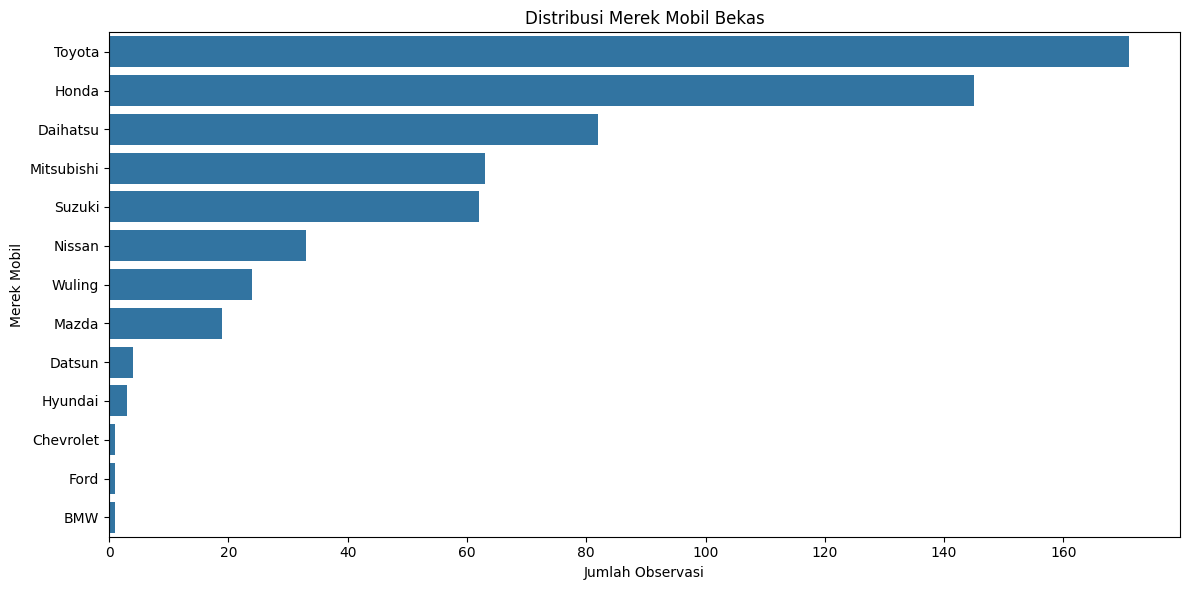

In [ ]:
# Menghitung jumlah setiap merek mobil
brand_counts = df["brand"].value_counts()

# Menghitung persentase setiap merek
brand_percentage = (
    df["brand"].value_counts(normalize=True) * 100
)

# Menggabungkan hasil ke dalam tabel
brand_distribution = pd.DataFrame({
    "Jumlah": brand_counts,
    "Persentase (%)": brand_percentage.round(2)
})

display(brand_distribution)


### 2.4.2 Distribusi Lokasi 

In [16]:
# Menghitung jumlah kendaraan berdasarkan lokasi
location_counts = df["location"].value_counts()

# Menghitung persentase setiap lokasi
location_percentage = (
    df["location"].value_counts(normalize=True) * 100
)

# Membuat tabel distribusi lokasi
location_distribution = pd.DataFrame({
    "Jumlah": location_counts,
    "Persentase (%)": location_percentage.round(2)
})

display(location_distribution)

,Jumlah,Persentase (%)
location,,
Bogor,104,17.08
Tangerang Selatan,98,16.09
Bekasi,68,11.17
Jakarta Utara,54,8.87
Unknown,52,8.54
Jakarta Timur,50,8.21
Jakarta Barat,45,7.39
Bandung,45,7.39
Depok,33,5.42


In [17]:
# Daftar wilayah Jabodetabek yang terdapat dalam dataset
jabodetabek = [
    "Bogor",
    "Tangerang Selatan",
    "Bekasi",
    "Jakarta Utara",
    "Jakarta Timur",
    "Jakarta Barat",
    "Depok",
    "Jakarta Selatan",
    "Jakarta Pusat"
]

# Menghitung jumlah kendaraan dari Jabodetabek
jumlah_jabodetabek = df["location"].isin(
    jabodetabek
).sum()

# Menghitung persentase kendaraan dari Jabodetabek
persentase_jabodetabek = (
    jumlah_jabodetabek / len(df)
) * 100

print("Jumlah kendaraan Jabodetabek:", jumlah_jabodetabek)

print(
    "Persentase kendaraan Jabodetabek:",
    round(persentase_jabodetabek, 2), "%"
)

Jumlah kendaraan Jabodetabek: 495
Persentase kendaraan Jabodetabek: 81.28 %


### 2.4.3 Distribusi Tahun Produksi Kendaraan

year
2010      2
2011      1
2012      3
2013      7
2014     27
2015     25
2016     53
2017     79
2018    143
2019    150
2020     53
2021     47
2022     18
2023      1
Name: count, dtype: int64

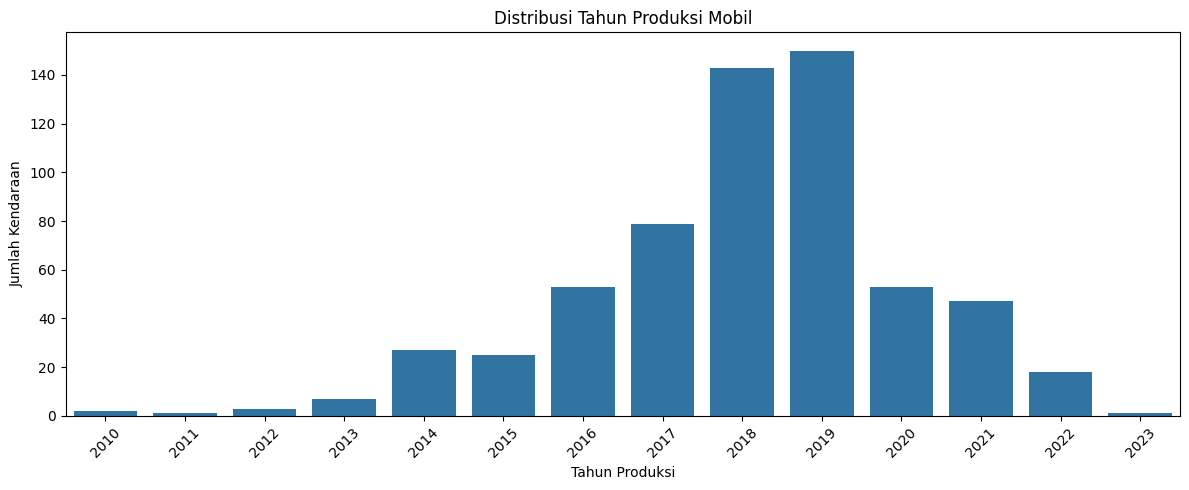

In [ ]:
# Menghitung jumlah kendaraan berdasarkan tahun produksi
year_counts = df["year"].value_counts().sort_index()

display(year_counts)


## 2.5 Analisis Representativitas dan Potensi Bias Sample
Berdasarkan hasil pemeriksaan terhadap 609 observasi, dataset Used Car Listings in Indonesia menunjukkan adanya ketimpangan distribusi pada beberapa karakteristik kendaraan.

Dari sisi merek, Toyota dan Honda mendominasi dengan proporsi gabungan sebesar 51,89%. Sebaliknya, beberapa merek seperti Chevrolet, Ford, dan BMW hanya memiliki satu observasi. Kondisi ini menunjukkan bahwa representasi setiap merek dalam dataset belum merata.

Dari sisi geografis, sebanyak 495 observasi atau 81,28% berasal dari wilayah Jabodetabek. Selain itu, terdapat 52 observasi atau 8,54% dengan lokasi yang tidak diketahui. Konsentrasi tersebut menunjukkan bahwa cakupan geografis dataset belum merata di seluruh Indonesia.

Dari sisi tahun produksi, kendaraan tahun 2017 hingga 2019 mencakup sekitar 61,08% dari keseluruhan observasi. Dengan demikian, karakteristik kendaraan dalam dataset lebih banyak merepresentasikan mobil pada periode tersebut.

Berdasarkan temuan tersebut, terdapat beberapa potensi bias sampel, yaitu bias geografis, bias representasi merek, bias periode produksi, dan keterbatasan informasi lokasi. Selain itu, karena dataset berasal dari kumpulan listing kendaraan, harga yang tercatat perlu diperlakukan sebagai harga penawaran dan belum tentu mencerminkan harga transaksi aktual.

Oleh karena itu, dataset ini belum dapat dianggap sepenuhnya representatif terhadap seluruh pasar mobil bekas di Indonesia. Model prediksi yang dikembangkan perlu mempertimbangkan keterbatasan cakupan sampel tersebut, terutama ketika digunakan untuk memprediksi harga kendaraan dari wilayah atau merek yang kurang terwakili. 